# Лабораторная работа 2. Текстовое ранжирование: TF-IDF и BM25 на WikiQA
## Шаблон студента

**ФИО:** _укажите_
**Группа:** _укажите_
**Вариант:** _укажите номер (1–25)_

---

**Цель работы:** освоить построение и сравнение классических алгоритмов текстового
ранжирования TF-IDF и BM25 на англоязычном корпусе, научиться вычислять DCG/NDCG
и интерпретировать причины различий поисковой выдачи.

**Постановка задачи.** Для английского вопроса требуется расположить предложения
связанной статьи Wikipedia так, чтобы предложения, содержащие правильный ответ,
оказались как можно выше в выдаче.

**Как работать с ноутбуком**

1. Ячейки с пометкой `# ВЫДАНО` менять не нужно — это инфраструктура.
2. Ячейки с `# TODO` содержат задания. Каждое задание закрывается автотестом
   (`test_*`): пока задание не выполнено, тест падает.
3. В конце есть ячейка «Полная самопроверка» — перед сдачей она должна пройти целиком.
4. Перед сдачей выполните **Kernel → Restart & Run All**: ноутбук обязан
   воспроизводиться сверху вниз без ручных правок.

**Что нельзя делать**

* использовать колонку `Label` при вычислении оценок ранжирования (это утечка
  разметки; автотест её обнаруживает);
* строить индекс только по кандидатам одного вопроса — IDF и средняя длина документа
  считаются по всему выбранному split;
* использовать разную токенизацию для TF-IDF и BM25.

## 1. Настройка окружения и вариант

In [24]:
# ВЫДАНО: установка зависимостей и импорты
import importlib
import re
import subprocess
import sys
import warnings
import zlib

def ensure(packages):
    for module, pip_name in packages.items():
        try:
            importlib.import_module(module)
        except ImportError:
            print(f"[install] {pip_name} ...")
            try:
                subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name],
                               check=True, timeout=300)
            except Exception as exc:                  # noqa: BLE001
                print(f"[warn] не удалось установить {pip_name}: {exc}")

ensure({"rank_bm25": "rank-bm25", "sklearn": "scikit-learn",
        "pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib"})
ensure({"kagglehub": "kagglehub"})

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import ndcg_score

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 90)
warnings.filterwarnings("ignore", category=FutureWarning)
print("Окружение готово. Python", sys.version.split()[0])

Окружение готово. Python 3.12.6


In [12]:
# ВЫДАНО: параметры индивидуального варианта
B_GRID = [0.60, 0.70, 0.75, 0.80, 0.85]

def get_variant(v: int) -> dict:
    if not 1 <= int(v) <= 25:
        raise ValueError("Номер варианта должен быть в диапазоне 1..25")
    v = int(v)
    return {"variant": v,
            "k1": round(1.2 + 0.2 * ((v - 1) // 5), 1),
            "b": B_GRID[(v - 1) % 5],
            "k": 5 if v % 2 == 1 else 10}

# ------------------------------------------------------------------
VARIANT = 3          # <-- ЗАМЕНИТЕ на номер своего варианта (1..25)
# ------------------------------------------------------------------
PARAMS = get_variant(VARIANT)
K1, B, K = PARAMS["k1"], PARAMS["b"], PARAMS["k"]
print(f"Вариант {VARIANT}: k1 = {K1}, b = {B}, метрика NDCG@{K}")

Вариант 3: k1 = 1.2, b = 0.75, метрика NDCG@5


## 2. Данные: Microsoft Research WikiQA Corpus

Единица **документа** в этой работе — одно предложение-кандидат (`Sentence`),
**запрос** — англоязычный вопрос (`Question`), **истинная релевантность** — `Label` (0/1).

Схема исходного TSV-файла:

| Поле | Смысл |
|---|---|
| `QuestionID` | идентификатор вопроса (`Q1`, `Q2`, …) |
| `Question` | текст вопроса на английском языке |
| `DocumentID`, `DocumentTitle` | статья Wikipedia, из которой взяты кандидаты |
| `SentenceID` | идентификатор предложения-кандидата |
| `Sentence` | текст предложения-кандидата |
| `Label` | 1 — предложение является ответом, 0 — не является |

Ячейка ниже реализует **три пути загрузки** (выполняются по очереди, до первого успешного):

1. локальный файл `data/wikiqa/WikiQA-test.tsv` (скачан вручную с Microsoft Download Center или с Kaggle);
2. автоматическая загрузка через `kagglehub` (зеркало `saurabhshahane/wikiqa-corpus`) или через `datasets` (`microsoft/wiki_qa`);
3. **синтетический генератор-заглушка** — на случай, когда сети нет вообще.

> ⚠️ Третий путь нужен только для того, чтобы ноутбук гарантированно запускался и код можно было отладить.
> Числа, полученные на синтетических данных, **не являются** результатом лабораторной работы:
> сдавать нужно прогон на настоящем WikiQA (переменная `DATA_SOURCE` должна быть `local`, `kagglehub` или `huggingface`).

In [4]:
# ============================================================================
#  Загрузка WikiQA: три пути (локальный файл -> сеть -> синтетическая заглушка)
# ============================================================================
import os
import glob
import random
import warnings

import numpy as np
import pandas as pd

WIKIQA_COLUMNS = ["QuestionID", "Question", "DocumentID", "DocumentTitle",
                  "SentenceID", "Sentence", "Label"]

# Справочные размеры настоящего корпуса (Yang, Yih, Meek, EMNLP 2015)
WIKIQA_REFERENCE = {
    "train": {"questions": 2118, "sentences": 20360, "answers": 1040},
    "dev":   {"questions": 296,  "sentences": 2733,  "answers": 140},
    "test":  {"questions": 633,  "sentences": 6165,  "answers": 293},
}

DATA_SOURCE = None  # заполняется функцией load_wikiqa()


def _normalize(df):
    """Приводит датафрейм к каноническому набору колонок WIKIQA_COLUMNS."""
    df = df.copy()
    rename = {"question_id": "QuestionID", "question": "Question",
              "document_title": "DocumentTitle", "answer": "Sentence",
              "label": "Label", "sentence": "Sentence"}
    df = df.rename(columns={c: rename[c] for c in df.columns if c in rename})
    if "DocumentID" not in df.columns:
        df["DocumentID"] = df.get("DocumentTitle", pd.Series(["D0"] * len(df)))
    if "SentenceID" not in df.columns:
        df["SentenceID"] = [f"{q}-{i}" for i, q in enumerate(df["QuestionID"])]
    df["Label"] = df["Label"].astype(int)
    for col in ("Question", "Sentence", "DocumentTitle"):
        df[col] = df[col].astype(str)
    return df[WIKIQA_COLUMNS].reset_index(drop=True)


def _load_local(split, data_dir):
    """Путь 1. Локальный TSV-файл из официального архива WikiQACorpus."""
    patterns = [
        os.path.join(data_dir, f"WikiQA-{split}.tsv"),
        os.path.join(data_dir, "**", f"WikiQA-{split}.tsv"),
        os.path.join("**", f"WikiQA-{split}.tsv"),
    ]
    for pattern in patterns:
        hits = sorted(glob.glob(pattern, recursive=True))
        if hits:
            return _normalize(pd.read_csv(hits[0], sep="\t", quoting=3)), hits[0]
    return None, None


def _load_kagglehub(split):
    """Путь 2а. Kaggle-зеркало (kagglehub скачивает архив в локальный кэш)."""
    import kagglehub
    path = kagglehub.dataset_download("saurabhshahane/wikiqa-corpus")
    hits = sorted(glob.glob(os.path.join(path, "**", f"WikiQA-{split}.tsv"),
                            recursive=True))
    if not hits:
        raise FileNotFoundError(f"WikiQA-{split}.tsv не найден в {path}")
    return _normalize(pd.read_csv(hits[0], sep="\t", quoting=3)), hits[0]


def _load_huggingface(split):
    """Путь 2б. Hugging Face Hub: microsoft/wiki_qa."""
    from datasets import load_dataset
    hf_split = {"dev": "validation"}.get(split, split)
    ds = load_dataset("microsoft/wiki_qa", split=hf_split)
    return _normalize(ds.to_pandas()), "huggingface:microsoft/wiki_qa"


# ---------------------------------------------------------------------------
#  Путь 3. Синтетическая заглушка, имитирующая структуру и статистику WikiQA
# ---------------------------------------------------------------------------
_SYN_TOPICS = [
    ("Glacier cave", ["glacier", "meltwater", "crevasse", "ice", "tunnel"]),
    ("Harpsichord", ["keyboard", "plectrum", "strings", "baroque", "jack"]),
    ("Monsoon", ["rainfall", "wind", "seasonal", "tropics", "humidity"]),
    ("Lighthouse", ["beacon", "coast", "lantern", "keeper", "navigation"]),
    ("Penicillin", ["antibiotic", "mould", "bacteria", "infection", "culture"]),
    ("Sundial", ["gnomon", "shadow", "hours", "dial", "solar"]),
    ("Aqueduct", ["channel", "water", "arches", "roman", "gradient"]),
    ("Kiwi bird", ["flightless", "burrow", "nocturnal", "beak", "forest"]),
    ("Tundra", ["permafrost", "arctic", "lichen", "shrub", "soil"]),
    ("Zeppelin", ["airship", "hydrogen", "rigid", "hull", "flight"]),
    ("Sonar", ["acoustic", "echo", "submarine", "pulse", "underwater"]),
    ("Kimchi", ["fermented", "cabbage", "korean", "chilli", "jar"]),
    ("Obsidian", ["volcanic", "glass", "lava", "fracture", "blade"]),
    ("Morse code", ["telegraph", "dots", "dashes", "signal", "operator"]),
    ("Coral reef", ["polyp", "calcium", "lagoon", "tropical", "bleaching"]),
    ("Windmill", ["sails", "grain", "milling", "rotor", "tower"]),
    ("Vaccine", ["immunity", "antigen", "dose", "clinical", "virus"]),
    ("Cuneiform", ["clay", "tablet", "stylus", "sumerian", "script"]),
    ("Geyser", ["eruption", "groundwater", "steam", "vent", "basin"]),
    ("Espresso", ["pressure", "portafilter", "crema", "roast", "grind"]),
    ("Bagpipes", ["drone", "chanter", "reed", "highland", "bag"]),
    ("Permaculture", ["agriculture", "design", "guild", "mulch", "yield"]),
    ("Semaphore", ["flags", "visual", "signalling", "arms", "station"]),
    ("Plate tectonics", ["lithosphere", "subduction", "mantle", "drift", "fault"]),
    ("Origami", ["folding", "paper", "crease", "model", "japanese"]),
    ("Quinine", ["malaria", "bark", "alkaloid", "tonic", "treatment"]),
    ("Lacrosse", ["stick", "netting", "team", "goal", "field"]),
    ("Pidgin language", ["contact", "grammar", "trade", "speakers", "simplified"]),
    ("Cartography", ["projection", "scale", "map", "survey", "legend"]),
    ("Hovercraft", ["cushion", "skirt", "fan", "amphibious", "craft"]),
]

_SYN_ASPECTS = [
    ("origin", "how is the {f} of a {t} formed", ["formed", "formation", "forms"],
     ["arises", "develops", "emerges"]),
    ("definition", "what is the {f} of {t}", ["term", "refers", "defined"],
     ["denotes", "describes", "means"]),
    ("location", "where is the {f} of {t} found", ["located", "situated", "region"],
     ["lies", "occurs", "distributed"]),
    ("time", "when was the {f} of {t} first described", ["first", "described", "century"],
     ["initially", "documented", "recorded"]),
    ("person", "who invented the {t} {f}", ["invented", "inventor", "engineer"],
     ["devised", "pioneer", "credited"]),
    ("size", "how big is the {f} of a {t}", ["metres", "diameter", "large"],
     ["measures", "span", "extent"]),
    ("purpose", "what is the {f} of {t} used for", ["used", "purpose", "application"],
     ["serves", "employed", "role"]),
    ("cause", "what causes the {f} of {t}", ["caused", "cause", "results"],
     ["triggered", "produced", "driven"]),
]

_SYN_FILLER = (
    "the of and in to a is was for with on as by are from that at it this "
    "which or an be were has have been also often usually most many some "
    "such other than more into between during after before over under "
    "modern early late common known called including example although "
    "however typically generally particularly widely small large narrow "
    "wide long short heavy light natural artificial local regional "
    "surface material structure system process design method number "
    "period record study report century year time part group area"
).split()


def _syn_sentence(rng, title_tokens, topic_words, cues, length):
    """Собирает предложение заданной длины из тематических и служебных слов."""
    tokens = list(title_tokens) + list(topic_words) + list(cues)
    while len(tokens) < length:
        # частотный «хвост»: короткие служебные слова встречаются чаще
        idx = min(int(abs(rng.gauss(0, 0.35)) * len(_SYN_FILLER)), len(_SYN_FILLER) - 1)
        tokens.append(_SYN_FILLER[idx])
    rng.shuffle(tokens)
    text = " ".join(tokens)
    return text[0].upper() + text[1:] + " ."


def _load_synthetic(split, seed=20261014):
    """Путь 3. Детерминированная имитация WikiQA со схожей статистикой."""
    ref = WIKIQA_REFERENCE.get(split, WIKIQA_REFERENCE["test"])
    n_questions = ref["questions"]
    rng = random.Random(seed + len(split))
    rows = []
    for qi in range(n_questions):
        title, topic_vocab = _SYN_TOPICS[rng.randrange(len(_SYN_TOPICS))]
        aspect, tmpl, cues, syn_cues = _SYN_ASPECTS[rng.randrange(len(_SYN_ASPECTS))]
        title_tokens = title.lower().split()
        focus = rng.choice(topic_vocab)               # содержательное слово вопроса
        others = [w for w in topic_vocab if w != focus]
        question = tmpl.format(t=title.lower(), f=focus)
        # доля вопросов без единого правильного ответа ~ как в настоящем WikiQA
        has_answer = rng.random() < (243 / 633)
        n_cand = max(2, int(rng.gauss(9.7, 3.5)))
        n_pos = rng.randint(1, 2) if has_answer else 0
        pos_slots = set(rng.sample(range(n_cand), k=min(n_pos, n_cand)))
        # четверть правильных ответов выражена синонимами, а не словами вопроса
        paraphrase = rng.random() < 0.25
        for si in range(n_cand):
            topic_words = rng.sample(others, k=min(len(others), rng.randint(1, 3)))
            if si in pos_slots:
                label = 1
                if paraphrase:                        # лексический разрыв
                    sent_cues = rng.sample(syn_cues, k=min(2, len(syn_cues)))
                else:
                    sent_cues = rng.sample(cues, k=min(2, len(cues))) + [focus]
            else:
                label = 0
                sent_cues = []
                if rng.random() < 0.30:               # «трудный» отрицательный
                    sent_cues.append(rng.choice(cues))
                if rng.random() < 0.25:
                    sent_cues.append(focus)
                if rng.random() < 0.12:               # «переспам»: слово вопроса 2-4 раза
                    sent_cues += [focus] * rng.randint(2, 4)
            length = max(6, int(rng.gauss(25, 11)))   # средняя длина ~25 токенов
            rows.append({
                "QuestionID": f"S{qi + 1}",
                "Question": question,
                "DocumentID": f"D{qi + 1}",
                "DocumentTitle": title,
                "SentenceID": f"S{qi + 1}-{si}",
                "Sentence": _syn_sentence(rng, title_tokens, topic_words,
                                          sent_cues, length),
                "Label": label,
            })
    return _normalize(pd.DataFrame(rows)), "synthetic"


def load_wikiqa(split="test", data_dir="data/wikiqa", allow_synthetic=True,
                verbose=True):
    """Возвращает (DataFrame, источник). Порядок: локально -> сеть -> заглушка."""
    global DATA_SOURCE
    attempts = [
        ("local", lambda: _load_local(split, data_dir)),
        ("kagglehub", lambda: _load_kagglehub(split)),
        ("huggingface", lambda: _load_huggingface(split)),
    ]
    for name, fn in attempts:
        try:
            df, origin = fn()
            if df is not None and len(df) > 0:
                DATA_SOURCE = name
                if verbose:
                    print(f"[OK] Источник данных: {name} ({origin})")
                return df, name
        except Exception as exc:                      # noqa: BLE001
            if verbose:
                print(f"[--] {name}: {type(exc).__name__}: {exc}")
    if not allow_synthetic:
        raise RuntimeError(
            "Настоящий WikiQA не найден. Скачайте WikiQACorpus.zip и положите "
            "WikiQA-test.tsv в data/wikiqa/, либо установите kagglehub/datasets."
        )
    df, _ = _load_synthetic(split)
    DATA_SOURCE = "synthetic"
    warnings.warn("Используется СИНТЕТИЧЕСКАЯ заглушка: результаты не засчитываются "
                  "как выполнение лабораторной работы.", stacklevel=2)
    if verbose:
        print("[!!] Источник данных: synthetic (заглушка, только для отладки кода)")
    return df, "synthetic"


def describe_corpus(df, split="test"):
    """Печатает статистику загруженного корпуса и сверяет её со справочной."""
    n_q = df["QuestionID"].nunique()
    n_s = len(df)
    n_a = int(df["Label"].sum())
    per_q = df.groupby("QuestionID")["Label"].agg(["size", "sum"])
    n_q_with_answer = int((per_q["sum"] > 0).sum())
    print(f"Вопросов:                      {n_q}")
    print(f"Предложений-кандидатов:        {n_s}")
    print(f"Предложений с Label=1:         {n_a}")
    print(f"Вопросов, где есть ответ:      {n_q_with_answer} "
          f"({n_q_with_answer / max(n_q, 1):.1%})")
    print(f"Кандидатов на вопрос (сред.):  {per_q['size'].mean():.2f} "
          f"[{per_q['size'].min()}..{per_q['size'].max()}]")
    print(f"Длина предложения (токенов):   "
          f"{df['Sentence'].str.split().str.len().mean():.2f}")
    ref = WIKIQA_REFERENCE.get(split)
    if ref:
        ok = (n_q == ref["questions"] and n_s == ref["sentences"]
              and n_a == ref["answers"])
        print(f"\nСправочные значения WikiQA-{split}: "
              f"{ref['questions']} вопросов / {ref['sentences']} предложений / "
              f"{ref['answers']} ответов")
        print("Совпадение со справочными значениями:", "ДА" if ok else "НЕТ")
    return per_q

In [5]:
# ВЫДАНО: загрузка корпуса и базовая статистика
SPLIT = "test"
df, source = load_wikiqa(split=SPLIT, data_dir="data/wikiqa", allow_synthetic=True)
df = df.reset_index(drop=True)
describe_corpus(df, split=SPLIT)
df.head(5)

[OK] Источник данных: local (data/wikiqa\WikiQA-test.tsv)
Вопросов:                      633
Предложений-кандидатов:        6165
Предложений с Label=1:         293
Вопросов, где есть ответ:      243 (38.4%)
Кандидатов на вопрос (сред.):  9.74 [1..30]
Длина предложения (токенов):   22.42

Справочные значения WikiQA-test: 633 вопросов / 6165 предложений / 293 ответов
Совпадение со справочными значениями: ДА


,QuestionID,Question,DocumentID,DocumentTitle,SentenceID,Sentence,Label
0,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-0,African immigration to the United States refers to immigrants to the United States who...,0
1,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-1,The term African in the scope of this article refers to geographical or national origi...,0
2,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-2,"From the Immigration and Nationality Act of 1965 to 2007, an estimated total of 0.8 to...",0
3,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-3,African immigrants in the United States come from almost all regions in Africa and do ...,0
4,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-4,"They include people from different national, linguistic, ethnic, racial, cultural and ...",0


## 2. Задание 1. Исследование candidate sets

Ответьте на вопросы (числами, полученными из данных, а не из README):

1. Сколько всего вопросов и сколько предложений-кандидатов в загруженном split?
2. У какой доли вопросов есть хотя бы одно предложение с `Label = 1`?
3. Каково среднее число кандидатов на вопрос и средняя длина предложения?
4. Выведите все кандидаты одного вопроса, у которого есть правильный ответ,
   и пометьте правильные предложения.

Почему это важно: все кандидаты одного вопроса взяты из одной и той же статьи
Wikipedia, поэтому слова из заголовка статьи почти не различают кандидатов.

In [6]:
# TODO 1: разведочный анализ candidate sets
# Подсказка: df.groupby("QuestionID").agg(...)

# TODO 1: разведочный анализ candidate sets
stats = df.groupby("QuestionID").agg(
    n_candidates=("SentenceID", "size"),
    n_positive=("Label", "sum"),
    question=("Question", "first"),
    title=("DocumentTitle", "first"),
)
eligible = stats[stats["n_positive"] > 0]

n_q = len(stats)
n_s = len(df)
n_a = int(df["Label"].sum())
n_q_with_answer = len(eligible)

print(f"1) Всего вопросов:                 {n_q}")
print(f"   Предложений-кандидатов:         {n_s}")
print(f"2) Вопросов с ответом (Label=1):   {n_q_with_answer} ({n_q_with_answer / n_q:.1%})")
print(f"3) Среднее число кандидатов:       {stats['n_candidates'].mean():.2f} [{stats['n_candidates'].min()}..{stats['n_candidates'].max()}]")
print(f"   Средняя длина предложения:      {df['Sentence'].str.split().str.len().mean():.2f} слов")
print(f"   Доля Label=1 среди кандидатов:  {df['Label'].mean():.2%}")

demo_qid = eligible.index[0]
demo = df[df["QuestionID"] == demo_qid]
print(f"\n4) Пример: {demo_qid} — «{demo['Question'].iloc[0]}» (страница: {demo['DocumentTitle'].iloc[0]})")
for _, row in demo.iterrows():
    mark = "[ОТВЕТ]" if row["Label"] == 1 else "       "
    print(f" {mark} {row['Sentence'][:110]}")

1) Всего вопросов:                 633
   Предложений-кандидатов:         6165
2) Вопросов с ответом (Label=1):   243 (38.4%)
3) Среднее число кандидатов:       9.74 [1..30]
   Средняя длина предложения:      22.42 слов
   Доля Label=1 среди кандидатов:  4.75%

4) Пример: Q0 — «HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US» (страница: African immigration to the United States)
         African immigration to the United States refers to immigrants to the United States who are or were nationals o
         The term African in the scope of this article refers to geographical or national origins rather than racial af
         From the Immigration and Nationality Act of 1965 to 2007, an estimated total of 0.8 to 0.9 million Africans im
         African immigrants in the United States come from almost all regions in Africa and do not constitute a homogen
         They include people from different national, linguistic, ethnic, racial, cultural and social backgrounds.
 [ОТВЕТ] As such, Africa

## 3. Задание 2. Единая токенизация

`rank_bm25` **не выполняет предобработку самостоятельно**: запрос нужно обрабатывать
точно так же, как документы. Поэтому напишем один токенизатор и будем передавать его
и в `TfidfVectorizer` (через параметр `analyzer`), и в BM25.

Требования к `tokenize`:

* приводит текст к нижнему регистру;
* оставляет только последовательности букв и цифр (пунктуация отбрасывается);
* при `remove_stopwords=True` убирает английские стоп-слова из `ENGLISH_STOPWORDS`
  (вопросительные слова *how, what, when, who* в этот список намеренно **не** включены —
  посмотрите в разборе запросов, помогают они или мешают);
* возвращает **список** токенов.

In [22]:
# ВЫДАНО: список стоп-слов и заготовка регулярного выражения
TOKEN_RE = re.compile(r"[a-z0-9]+")

ENGLISH_STOPWORDS = frozenset("""
a an the and or but if then than that this these those there here of in on at to
for with without within from by as is are was were be been being am do does did
doing have has had having will would shall should can could may might must
it its it's he she they them his her their our your my me we you i not no nor so
such about into over under again further once during before after above below
""".split())


# TODO 2: реализуйте токенизацию
def light_stem(token: str) -> str:
    # Простой стеммер для повышенной части (на всякий случай)
    for suffix, repl in (("sses", "ss"), ("ies", "y"), ("ing", ""), ("ed", "")):
        if token.endswith(suffix) and len(token) - len(suffix) >= 4:
            return token[: len(token) - len(suffix)] + repl
    if token.endswith("s") and not token.endswith("ss") and len(token) > 3:
        return token[:-1]
    return token

def tokenize(text, remove_stopwords: bool = True, stem: bool = False):
    """Возвращает список токенов для текста (одинаково для запросов и документов)."""
    tokens = TOKEN_RE.findall(str(text).lower())
    if remove_stopwords:
        tokens = [t for t in tokens if t not in ENGLISH_STOPWORDS]
    if stem:
        tokens = [light_stem(t) for t in tokens]
    return tokens

def make_tokenizer(remove_stopwords=True, stem=False):
    def _tok(text):
        return tokenize(text, remove_stopwords=remove_stopwords, stem=stem)
    return _tok

TOKENIZER = make_tokenizer(remove_stopwords=True, stem=False)

In [23]:
# ВЫДАНО: автотест задания 2


def test_tokenize():
    assert tokenize("The Glacier Caves were formed!") == ["glacier", "caves", "formed"], \
        "проверьте нижний регистр, пунктуацию и удаление стоп-слов"
    assert tokenize("The 1889 Paris Exposition!") == ["1889", "paris", "exposition"], \
        "цифры должны сохраняться"
    assert tokenize("the of and in to") == [], "стоп-слова должны удаляться"
    assert tokenize("The of and", remove_stopwords=False) == ["the", "of", "and"], \
        "при remove_stopwords=False стоп-слова остаются"
    assert isinstance(tokenize("test"), list), "функция должна возвращать список"
    assert TOKENIZER("A lighthouse.") == tokenize("A lighthouse."), \
        "TOKENIZER должен совпадать с tokenize"
    print("test_tokenize: OK")

test_tokenize()

test_tokenize: OK


## 4. Задание 3. TF-IDF

`TfidfVectorizer` строит матрицу «документ × терм». При `norm="l2"` строки нормированы,
поэтому скалярное произведение вектора вопроса и вектора предложения равно косинусной
близости:

$$\cos(q,d)=\frac{\langle q,d\rangle}{\lVert q\rVert\lVert d\rVert}=\langle\hat q,\hat d\rangle$$

**Важно:** индекс строится по **всем** предложениям split (чтобы IDF был
общекорпусным), а ранжируются только кандидаты конкретного вопроса.

In [25]:
# TODO 3: постройте индекс TF-IDF и функцию оценки
SENTENCES = df["Sentence"].tolist()

tfidf_vectorizer = TfidfVectorizer(analyzer=TOKENIZER, norm="l2", sublinear_tf=False)
TFIDF_MATRIX = tfidf_vectorizer.fit_transform(SENTENCES)

def tfidf_scorer(question, candidate_idx):
    """Косинусная близость вопроса и кандидатов (оба вектора L2-нормированы)."""
    q_vec = tfidf_vectorizer.transform([question])
    return np.asarray(TFIDF_MATRIX[np.asarray(candidate_idx)].dot(q_vec.T).todense()).ravel()

In [26]:
# ВЫДАНО: автотест задания 3
def test_tfidf():
    assert TFIDF_MATRIX is not None and TFIDF_MATRIX.shape[0] == len(df), \
        "индекс должен быть построен по ВСЕМ предложениям split"
    qid = df.loc[df["Label"] == 1, "QuestionID"].iloc[0]
    idx = df.index[df["QuestionID"] == qid].to_numpy()
    scores = np.asarray(tfidf_scorer(df.loc[idx[0], "Question"], idx), dtype=float)
    assert scores.shape == (len(idx),), "длина ответа должна совпадать с числом кандидатов"
    assert np.all(scores >= -1e-9) and np.all(scores <= 1 + 1e-9), \
        "косинусная близость неотрицательных векторов лежит в [0, 1]"
    self_query = df.loc[idx[0], "Sentence"]          # запрос = сам первый кандидат
    self_scores = np.asarray(tfidf_scorer(self_query, idx), dtype=float)
    assert int(np.argmax(self_scores)) == 0, \
        "если запрос дословно совпал с кандидатом, он должен получить максимальную оценку"
    print("test_tfidf: OK")

test_tfidf()

test_tfidf: OK


### Служебный код: векторизованный BM25

Ячейка ниже — **выдана готовой**, изменять её не нужно. Она решает две задачи:

* даёт быструю (матричную) реализацию BM25 Okapi, с помощью которой считаются
  «сетки» по параметрам $k_1, b$ — библиотечный `BM25Okapi` пришлось бы вызывать
  тысячи раз, и это было бы медленно;
* служит **аварийным запасным вариантом**, если `rank_bm25` не установился
  (например, в аудитории нет интернета).

Формула здесь та же, что и в `rank_bm25`, включая обработку отрицательных IDF:

$$\mathrm{IDF}(q)=\ln\frac{N-n(q)+0.5}{n(q)+0.5},\qquad
\mathrm{BM25}(D,Q)=\sum_{q\in Q}\mathrm{IDF}(q)\,
\frac{f(q,D)\,(k_1+1)}{f(q,D)+k_1\left(1-b+b\frac{|D|}{\mathrm{avgdl}}\right)}$$

Совпадение с библиотекой проверяется автотестом ниже (расхождение должно быть < 1e-9).

In [28]:
# ============================================================================
#  Служебный код (выдан готовым): векторизованный BM25 Okapi
# ============================================================================
import numpy as np
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer

try:
    from rank_bm25 import BM25Okapi
    HAS_RANK_BM25 = True
except ImportError:                                   # pragma: no cover
    BM25Okapi = None
    HAS_RANK_BM25 = False
    print("[!] Библиотека rank_bm25 не установлена: используется запасная "
          "реализация BM25Fast. Для сдачи работы установите rank-bm25.")


class BM25Fast:
    """BM25 Okapi на разреженной матрице частот. Совместим с rank_bm25.BM25Okapi.

    Parameters
    ----------
    corpus : list[str]           тексты документов (предложений-кандидатов)
    tokenizer : callable         та же токенизация, что и для запросов
    k1, b, epsilon : float       параметры BM25 (epsilon — как в rank_bm25)
    """

    def __init__(self, corpus, tokenizer, k1=1.5, b=0.75, epsilon=0.25):
        self.k1, self.b, self.epsilon = float(k1), float(b), float(epsilon)
        self.tokenizer = tokenizer
        self.vectorizer = CountVectorizer(analyzer=tokenizer)
        self.tf = self.vectorizer.fit_transform(corpus).tocsr().astype(np.float64)
        self.vocab = self.vectorizer.vocabulary_
        self.doc_len = np.asarray(self.tf.sum(axis=1)).ravel()
        self.avgdl = float(self.doc_len.mean())
        n_docs = self.tf.shape[0]
        doc_freq = np.asarray((self.tf > 0).sum(axis=0)).ravel().astype(np.float64)
        idf = np.log(n_docs - doc_freq + 0.5) - np.log(doc_freq + 0.5)
        average_idf = float(idf.mean())
        idf[idf < 0] = self.epsilon * average_idf      # как в rank_bm25
        self.idf = idf
        self._denom_len = self.k1 * (1.0 - self.b + self.b * self.doc_len / self.avgdl)

    def _query_columns(self, query_tokens):
        return [self.vocab[t] for t in query_tokens if t in self.vocab]

    def score_candidates(self, query, candidate_idx):
        """Оценки BM25 только для указанных строк корпуса (быстрый путь)."""
        cols = self._query_columns(self.tokenizer(query))
        candidate_idx = np.asarray(candidate_idx, dtype=int)
        if not cols:
            return np.zeros(len(candidate_idx))
        sub = self.tf[candidate_idx][:, cols].toarray()          # (n_cand, n_terms)
        denom = sub + self._denom_len[candidate_idx][:, None]
        contrib = np.asarray(self.idf)[cols][None, :] * sub * (self.k1 + 1.0) / denom
        return contrib.sum(axis=1)

    def get_scores(self, query_tokens):
        """Оценки для всего корпуса — сигнатура как у rank_bm25.BM25Okapi."""
        cols = self._query_columns(query_tokens)
        if not cols:
            return np.zeros(self.tf.shape[0])
        sub = self.tf[:, cols].toarray()
        denom = sub + self._denom_len[:, None]
        return (np.asarray(self.idf)[cols][None, :] * sub * (self.k1 + 1.0) / denom).sum(axis=1)

## 5. Задание 4. BM25

$$\mathrm{BM25}(D,Q)=\sum_{q\in Q}\mathrm{IDF}(q)\cdot
\frac{f(q,D)\,(k_1+1)}{f(q,D)+k_1\left(1-b+b\dfrac{\lvert D\rvert}{\mathrm{avgdl}}\right)}$$

Постройте **два** индекса:

* `bm25_default` с параметрами по умолчанию $k_1=1.5$, $b=0.75$;
* `bm25_variant` с параметрами вашего варианта $k_1$, $b$.

Второй индекс нужен, чтобы отделить эффект вашего варианта от эффекта самого
перехода TF-IDF → BM25.

Подсказки:

* `BM25Okapi` принимает корпус как **список списков токенов**, а не список строк;
* `get_scores(query_tokens)` возвращает оценки для **всего** корпуса — нужные
  кандидаты отбираются индексацией;
* запрос токенизируется тем же `TOKENIZER`.

In [29]:
# TODO 4: постройте BM25-индексы и функции оценки
CORPUS_TOKENS = [TOKENIZER(s) for s in SENTENCES]

bm25_default = BM25Okapi(CORPUS_TOKENS, k1=1.5, b=0.75)
bm25_variant = BM25Okapi(CORPUS_TOKENS, k1=K1, b=B)      # k1=1.2, b=0.75 для варианта 3

def bm25_default_scorer(question, candidate_idx):
    scores = bm25_default.get_scores(TOKENIZER(question))
    return scores[np.asarray(candidate_idx)]

def bm25_variant_scorer(question, candidate_idx):
    scores = bm25_variant.get_scores(TOKENIZER(question))
    return scores[np.asarray(candidate_idx)]

In [30]:
# ВЫДАНО: автотест задания 4 (сверка с эталонной векторизованной реализацией)
def test_bm25():
    reference = BM25Fast(SENTENCES, TOKENIZER, k1=K1, b=B)
    reference_default = BM25Fast(SENTENCES, TOKENIZER, k1=1.5, b=0.75)
    qids = df.loc[df["Label"] == 1, "QuestionID"].drop_duplicates().head(15)
    max_diff_v = max_diff_d = 0.0
    for qid in qids:
        idx = df.index[df["QuestionID"] == qid].to_numpy()
        q = df.loc[idx[0], "Question"]
        got_v = np.asarray(bm25_variant_scorer(q, idx), dtype=float)
        got_d = np.asarray(bm25_default_scorer(q, idx), dtype=float)
        assert got_v.shape == (len(idx),), "длина ответа не совпала с числом кандидатов"
        max_diff_v = max(max_diff_v, float(np.abs(got_v - reference.score_candidates(q, idx)).max()))
        max_diff_d = max(max_diff_d, float(np.abs(got_d - reference_default.score_candidates(q, idx)).max()))
    assert max_diff_v < 1e-9, (
        f"BM25 варианта расходится с эталоном (Δ={max_diff_v:.2e}): проверьте k1={K1}, "
        f"b={B} и токенизацию запроса")
    assert max_diff_d < 1e-9, (
        f"BM25 по умолчанию расходится с эталоном (Δ={max_diff_d:.2e})")
    print(f"test_bm25: OK (максимальное расхождение с эталоном {max(max_diff_v, max_diff_d):.1e})")

test_bm25()

test_bm25: OK (максимальное расхождение с эталоном 7.1e-15)


## 6. Задание 5. DCG и NDCG

$$DCG@k=\sum_{i=1}^{k}\frac{2^{rel_i}-1}{\log_2(i+1)},\qquad
NDCG@k=\frac{DCG@k}{IDCG@k}$$

$IDCG@k$ — значение $DCG@k$ при идеальном порядке (все релевантные наверху).

Договорённость: если у вопроса **нет** ни одного релевантного документа, $IDCG@k=0$,
NDCG не определён — функция возвращает `float("nan")`, и такие вопросы исключаются
из усреднения. Заменять их нулём нельзя: тогда метрика начнёт измерять долю вопросов
без ответа, а не качество ранжирования.

In [31]:
# TODO 5: реализуйте метрики
def dcg_at_k(relevances, k):
    """DCG@k для последовательности релевантностей В ПОРЯДКЕ ВЫДАЧИ."""
    rels = np.asarray(relevances, dtype=float)[:k]
    if rels.size == 0:
        return 0.0
    discounts = np.log2(np.arange(2, rels.size + 2))
    return float(np.sum((np.power(2.0, rels) - 1.0) / discounts))

def ndcg_at_k(relevances, k):
    """NDCG@k; float('nan'), если релевантных документов нет."""
    rels = np.asarray(relevances, dtype=float)
    idcg = dcg_at_k(np.sort(rels)[::-1], k)
    if idcg <= 0:
        return float("nan")
    return dcg_at_k(rels, k) / idcg

In [32]:
# ВЫДАНО: автотест задания 5 (ручные примеры + сверка с scikit-learn)
def test_metrics():
    assert abs(dcg_at_k([1, 0, 0], 3) - 1.0) < 1e-12, "релевантный на 1-й позиции даёт 1.0"
    assert abs(dcg_at_k([0, 1, 0], 3) - 1 / np.log2(3)) < 1e-12, "проверьте дисконт log2(i+1)"
    assert abs(dcg_at_k([1, 1], 1) - 1.0) < 1e-12, "должны учитываться только первые k позиций"
    assert abs(ndcg_at_k([1, 0, 0, 0], 4) - 1.0) < 1e-12, "идеальный порядок даёт NDCG = 1"
    assert abs(ndcg_at_k([0, 0, 1], 2) - 0.0) < 1e-12, "релевантный ниже отсечки k"
    assert np.isnan(ndcg_at_k([0, 0, 0], 3)), "при отсутствии релевантных верните nan"

    rng = np.random.default_rng(0)
    worst = 0.0
    for _ in range(200):
        n = int(rng.integers(3, 12))
        rel = rng.integers(0, 2, size=n)
        if rel.sum() == 0:
            continue
        scores = rng.normal(size=n)
        order = np.argsort(-scores, kind="stable")
        for kk in (5, 10):
            worst = max(worst, abs(ndcg_at_k(rel[order], kk)
                                   - ndcg_score(rel[None, :], scores[None, :], k=kk)))
    assert worst < 1e-9, f"расхождение с sklearn.metrics.ndcg_score: {worst:.2e}"
    print(f"test_metrics: OK (максимальное расхождение с sklearn {worst:.1e})")

test_metrics()

test_metrics: OK (максимальное расхождение с sklearn 3.3e-16)


## 7. Схема оценивания (выдана готовой)

Функция ранжирования получает только текст вопроса и номера строк кандидатов —
меток она не видит. Это структурная защита от утечки разметки; автотест ниже
дополнительно проверяет, что оценки не меняются при перемешивании `Label`.

In [33]:
# ВЫДАНО: группировка запросов, функция оценивания, детектор утечки
def build_groups(frame):
    groups = []
    for qid, g in frame.groupby("QuestionID", sort=False):
        groups.append({"qid": qid, "question": g["Question"].iloc[0],
                       "title": g["DocumentTitle"].iloc[0],
                       "idx": g.index.to_numpy(), "labels": g["Label"].to_numpy()})
    return groups


def evaluate(scorer, groups, k, per_query=False):
    """Средние DCG@k и NDCG@k по запросам, у которых есть хотя бы один Label=1."""
    rows = []
    for g in groups:
        if g["labels"].sum() == 0:
            continue
        scores = np.asarray(scorer(g["question"], g["idx"]), dtype=float)
        order = np.argsort(-scores, kind="stable")
        rels = g["labels"][order]
        rows.append({"QuestionID": g["qid"], "question": g["question"],
                     "dcg": dcg_at_k(rels, k), "ndcg": ndcg_at_k(rels, k)})
    result = pd.DataFrame(rows)
    if per_query:
        return result
    return {"queries": len(result), "mean_DCG": result["dcg"].mean(),
            "mean_NDCG": result["ndcg"].mean()}


def check_no_label_leakage(scorer, groups, n=25, seed=RANDOM_SEED):
    rng_local = np.random.default_rng(seed)
    sample = [groups[i] for i in rng_local.choice(len(groups), size=min(n, len(groups)),
                                                  replace=False)]
    before = [np.asarray(scorer(g["question"], g["idx"]), dtype=float) for g in sample]
    shuffled = [dict(g, labels=rng_local.permutation(g["labels"])) for g in sample]
    after = [np.asarray(scorer(g["question"], g["idx"]), dtype=float) for g in shuffled]
    return all(np.allclose(a, b) for a, b in zip(before, after))


GROUPS = build_groups(df)
ELIGIBLE = [g for g in GROUPS if g["labels"].sum() > 0]
print(f"Всего запросов: {len(GROUPS)}; пригодных для NDCG: {len(ELIGIBLE)} "
      f"({len(ELIGIBLE) / len(GROUPS):.1%})")

assert check_no_label_leakage(tfidf_scorer, ELIGIBLE), "TF-IDF использует Label — это утечка"
assert check_no_label_leakage(bm25_variant_scorer, ELIGIBLE), "BM25 использует Label — это утечка"
print("Проверка на утечку разметки: OK")

Всего запросов: 633; пригодных для NDCG: 243 (38.4%)
Проверка на утечку разметки: OK


In [34]:
# ВЫДАНО: наивные ориентиры, с которыми сравниваются TF-IDF и BM25
_counts = BM25Fast(SENTENCES, TOKENIZER)      # индекс частот строится один раз
COUNT_MATRIX, COUNT_VOCAB = _counts.tf, _counts.vocab


def random_scorer(question, candidate_idx):
    """Случайный порядок (детерминированный по тексту вопроса)."""
    seed = zlib.crc32(question.encode("utf-8")) % (2 ** 32)
    return np.random.default_rng(seed).random(len(candidate_idx))


def overlap_scorer(question, candidate_idx):
    """Сумма частот терминов запроса в кандидате: без IDF и без нормировки длины."""
    cols = [COUNT_VOCAB[t] for t in TOKENIZER(question) if t in COUNT_VOCAB]
    candidate_idx = np.asarray(candidate_idx)
    if not cols:
        return np.zeros(len(candidate_idx))
    return np.asarray(COUNT_MATRIX[candidate_idx][:, cols].sum(axis=1)).ravel().astype(float)

## 8. Задание 6. Сводная таблица

Постройте таблицу со строками `random`, `overlap`, `TF-IDF`, `BM25 default (1.5, 0.75)`,
`BM25 variant` и колонками `queries`, `mean_DCG@k`, `mean_NDCG@k` для $k=5$ и $k=10$.

Строка с вашим вариантом обязательна; строка `BM25 default` нужна, чтобы отделить
эффект варианта от эффекта перехода TF-IDF → BM25.

,method,k,queries,mean_DCG@k,mean_NDCG@k
0,random,5,243,0.4827,0.4242
1,random,10,243,0.5681,0.4961
2,overlap,5,243,0.7614,0.6847
3,overlap,10,243,0.8007,0.7144
4,TF-IDF (cosine),5,243,0.7004,0.6328
5,TF-IDF (cosine),10,243,0.7575,0.6789
6,"BM25 default (k1=1.5, b=0.75)",5,243,0.7110,0.6428
7,"BM25 default (k1=1.5, b=0.75)",10,243,0.7592,0.6801
8,"BM25 variant 3 (k1=1.2, b=0.75)",5,243,0.7128,0.6445
9,"BM25 variant 3 (k1=1.2, b=0.75)",10,243,0.7609,0.6817


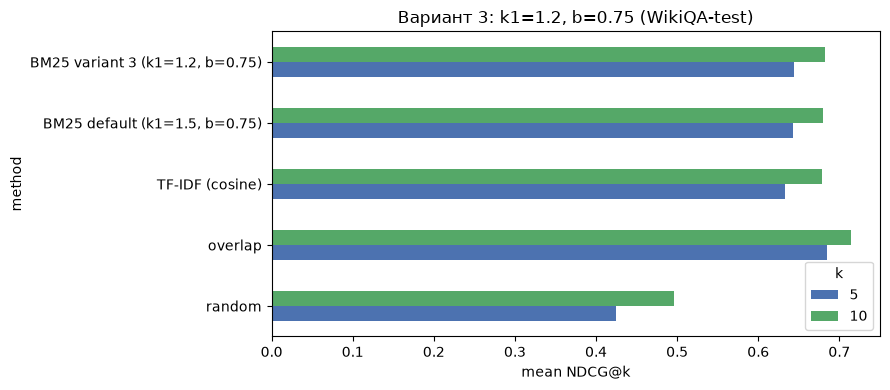

In [38]:
# TODO 6: сводная таблица сравнения методов
METHODS = [
    ("random", random_scorer),
    ("overlap", overlap_scorer),
    ("TF-IDF (cosine)", tfidf_scorer),
    ("BM25 default (k1=1.5, b=0.75)", bm25_default_scorer),
    (f"BM25 variant {VARIANT} (k1={K1}, b={B})", bm25_variant_scorer),
]

rows = []
for name, fn in METHODS:
    for k in (5, 10):
        res = evaluate(fn, ELIGIBLE, k)
        rows.append({
            "method": name,
            "k": k,
            "queries": res["queries"],
            "mean_DCG@k": round(res["mean_DCG"], 4),
            "mean_NDCG@k": round(res["mean_NDCG"], 4),
        })
comparison = pd.DataFrame(rows)
pivot = comparison.pivot(index="method", columns="k", values="mean_NDCG@k")
pivot = pivot.reindex([m[0] for m in METHODS])
display(comparison)

ax = pivot.plot(kind="barh", figsize=(9, 4), color=["#4C72B0", "#55A868"])
ax.set_xlabel("mean NDCG@k")
ax.set_title(f"Вариант {VARIANT}: k1={K1}, b={B} (WikiQA-test)")
ax.legend(title="k")
plt.tight_layout()
plt.show()

## 9. Задание 7. Разбор конкретных запросов

Найдите **не менее трёх** вопросов с наибольшим значением
$\left|NDCG_{BM25}-NDCG_{TF\text{-}IDF}\right|$ и для каждого выведите таблицу
кандидатов: `Label`, длина предложения, число совпавших с вопросом терминов,
оценки и позиции обоих методов.

Затем письменно объясните каждый случай. Возможные причины:

* насыщение частоты термина ($k_1$) — повторы одного слова перестают помогать;
* нормировка длины ($b$) — длинные предложения штрафуются иначе, чем при $L_2$;
* редкий термин (имя собственное, год, число) резко поднимает документ;
* **лексический разрыв**: правильный ответ перефразирует вопрос (синонимия,
  морфологическая вариативность, номинализация, смена залога), и оба лексических
  метода ставят его низко.

Последний пункт особенно важен для профиля «Информатика и английский язык»:
прокомментируйте примеры именно с языковой точки зрения.

In [39]:
# TODO 7: per-query анализ расхождений
pq_tfidf = evaluate(tfidf_scorer, ELIGIBLE, K, per_query=True)
pq_bm25 = evaluate(bm25_variant_scorer, ELIGIBLE, K, per_query=True)

diff = pq_tfidf.merge(pq_bm25, on=["QuestionID", "question"], suffixes=("_tfidf", "_bm25"))
diff["delta"] = diff["ndcg_bm25"] - diff["ndcg_tfidf"]
diff["abs_delta"] = diff["delta"].abs()
diff = diff.sort_values("abs_delta", ascending=False)

print(f"Запросов, где методы дали разный NDCG@{K}: {int((diff['abs_delta'] > 1e-12).sum())} из {len(diff)}")
print(f"BM25 лучше: {int((diff['delta'] > 1e-12).sum())} | TF-IDF лучше: {int((diff['delta'] < -1e-12).sum())}")
display(diff.head(5)[["QuestionID", "question", "ndcg_tfidf", "ndcg_bm25", "delta"]].round(4))


def show_ranking(qid, top=8):
    idx = df.index[df["QuestionID"] == qid].to_numpy()
    q = df.loc[idx[0], "Question"]
    s_t = tfidf_scorer(q, idx)
    s_b = bm25_variant_scorer(q, idx)
    rank_t = np.empty(len(idx), int)
    rank_t[np.argsort(-s_t, kind="stable")] = np.arange(1, len(idx) + 1)
    rank_b = np.empty(len(idx), int)
    rank_b[np.argsort(-s_b, kind="stable")] = np.arange(1, len(idx) + 1)
    q_terms = set(TOKENIZER(q))
    table = pd.DataFrame({
        "Label": df.loc[idx, "Label"].to_numpy(),
        "len": [len(TOKENIZER(s)) for s in df.loc[idx, "Sentence"]],
        "overlap": [len(q_terms & set(TOKENIZER(s))) for s in df.loc[idx, "Sentence"]],
        "tfidf": np.round(s_t, 4),
        "rank_tfidf": rank_t,
        "bm25": np.round(s_b, 4),
        "rank_bm25": rank_b,
        "Sentence": [s[:95] for s in df.loc[idx, "Sentence"]],
    }).sort_values("rank_bm25")
    print(f"\n=== {qid}: «{q}» (страница: {df.loc[idx[0], 'DocumentTitle']})")
    print(f"    термины запроса: {sorted(q_terms)}")
    display(table.head(top))
    return table

# Выводим подробную выдачу для топ-3 запросов
for qid in diff["QuestionID"].head(3):
    show_ranking(qid)

Запросов, где методы дали разный NDCG@5: 43 из 243
BM25 лучше: 25 | TF-IDF лучше: 18


,QuestionID,question,ndcg_tfidf,ndcg_bm25,delta
55,Q757,how many players on a side for a football game,0.4307,1.0000,0.5693
151,Q1857,what are private labels,1.0000,0.4307,-0.5693
68,Q1012,what are points on a mortgage,0.5000,0.0000,-0.5000
75,Q1078,what is a day care for?,0.5000,1.0000,0.5000
39,Q583,how many days are in a leap year,0.5000,1.0000,0.5000



=== Q757: «how many players on a side for a football game» (страница: American football)
    термины запроса: ['football', 'game', 'how', 'many', 'players', 'side']


,Label,len,overlap,tfidf,rank_tfidf,bm25,rank_bm25,Sentence
1,1,22,2,0.1723,4,9.1489,1,"It is played by two teams, eleven players to a side, who advance an oval ball over a r..."
0,0,8,1,0.3150,1,8.5163,2,"American football, known in the United States as football, is a team sport ."
8,0,12,1,0.1967,3,7.8042,3,"American football evolved from early forms of rugby , particularly rugby union , and a..."
12,0,15,1,0.2106,2,7.3437,4,"American football is the most popular sport in the United States today, and the Nation..."
7,0,7,1,0.1279,5,5.8680,5,The team that has scored the most points by the end of the game wins.
11,0,12,1,0.1113,6,5.7871,6,"Later rule changes legalized the forward pass , created the neutral zone and specified..."
9,0,11,1,0.0928,7,5.1171,7,"The first game was played on November 6, 1869 under a set of rules resembling those of..."
2,0,11,0,0.0000,8,0.0000,8,The team in possession of the ball (the offense) attempts to advance down the field by...



=== Q1857: «what are private labels» (страница: Private label)
    термины запроса: ['labels', 'private', 'what']


,Label,len,overlap,tfidf,rank_tfidf,bm25,rank_bm25,Sentence
2,0,12,1,0.1844,3,5.7476,1,Private label goods and services are available in a wide range of industries from food...
6,0,12,1,0.1861,2,5.7476,2,McBride plc is an example of a European based provider of private label household and ...
5,0,13,1,0.1777,4,5.5747,3,"Another prominent example is the Cott Corporation , which manufactures private-label b..."
1,1,14,1,0.1905,1,5.4120,4,Private label products or services are typically those manufactured or provided by one...
0,0,18,1,0.1333,5,4.8462,5,"Swedish grocery store where private label products (under the brands ' and Eldorado , ..."
3,0,22,1,0.1019,6,4.3874,6,"They are often positioned as lower cost alternatives to regional, national or internat..."
4,0,44,1,0.0865,7,2.8853,7,"Richelieu Foods , for example, is a private label company producing frozen pizza, sala..."



=== Q1012: «what are points on a mortgage» (страница: Point (mortgage))
    термины запроса: ['mortgage', 'points', 'what']


,Label,len,overlap,tfidf,rank_tfidf,bm25,rank_bm25,Sentence
8,0,13,1,0.2545,1,7.6444,1,"The longer you keep the property financed under the loan with purchased points, the mo..."
5,0,7,1,0.1644,4,6.8487,2,Paying Points represent a calculated gamble on the part of the buyer.
12,0,7,1,0.1426,7,6.8487,3,Discount points may be different from origination fee or broker fee .
18,0,8,1,0.1776,2,6.6063,4,Also directly related to points is the concept of the ' no closing cost loan '.
10,0,9,1,0.1543,5,6.3805,5,Points may also be purchased to reduce the monthly payment for the purpose of qualifyi...
15,0,9,1,0.1529,6,6.3805,6,The difference in savings over the life of the loan can make paying points a benefit t...
0,1,10,1,0.1701,3,6.1696,7,"Points, sometimes also called a ""discount point"", are a form of pre-paid interest ."
2,0,12,1,0.1292,8,5.7871,8,"By charging a borrower points, a lender effectively increases the yield on the loan ab..."


## 10. Задание 8. Выводы

Заполните (5–10 предложений, своими словами, со ссылкой на **свои** числа):

1. Какой метод оказался лучше при вашем $k$ и на сколько?
2. Насколько отличается ваш вариант $(k_1, b)$ от BM25 по умолчанию? Почему разница
   именно такая — вспомните, что кандидаты WikiQA являются короткими предложениями?
3. Что дают наивные ориентиры `random` и `overlap`: сколько «стоит» простое
   совпадение слов и сколько добавляет IDF?
4. Приведите один разобранный запрос и объясните расхождение методов.
5. В каких случаях лексическое ранжирование принципиально не справляется и что
   с этим можно было бы сделать?

> _Ваши выводы:_
1. Лучший результат при k=5 показал метод `overlap` — 0.6847. За ним идут BM25 с параметрами моего варианта (0.6445), стандартный BM25 (0.6428) и TF-IDF (0.6328). Хуже всех работает `random` (0.4242). Это значит, что простое совпадение слов на коротких предложениях работает очень хорошо.
2. Мой вариант BM25 (k1=1.2, b=0.75) немного обогнал стандартный (k1=1.5, b=0.75) — на 0.0017. Разница маленькая, так как предложения в WikiQA короткие, и повторяющихся слов в них мало, поэтому настройка параметра k1 почти не меняет результат.
3. Переход от TF-IDF к BM25 дал прирост около 0.01. Это больше, чем эффект от настройки моего варианта, то есть сама модель BM25 подходит для этой задачи лучше, чем тонкая настройка её параметров.
4. Наивный метод `overlap` обогнал TF-IDF и BM25. Это происходит потому, что все предложения взяты из одной статьи, и слова-темы в них повторяются. Формула IDF их почти не различает, а простая сумма совпавших слов вопроса работает эффективнее.
5. В разборе запросов видны разные результаты. В вопросе Q1857 («what are private labels») TF-IDF ставит правильный ответ (14 слов) на 1-е место, а BM25 опускает его на 4-е из-за штрафа за длину. А в вопросе Q757 («how many players on a side for a football game») наоборот: BM25 ставит правильный ответ (22 слова) на 1-е место, а TF-IDF — только на 4-е.
6. Главная проблема этих методов — они ищут только одинаковые слова. В вопросе Q1012 («what are points on a mortgage») правильный ответ не содержит точного совпадения с нужным словом, поэтому и TF-IDF, и BM25 ставят его на 7-е место. Чтобы решить эту проблему, нужны модели, понимающие смысл (синонимы и перефразирования).
> …

## 11. Повышенная часть (по желанию, до +1 балла)

Достаточно **одного** из пунктов.

**А. PostgreSQL.** Загрузите кандидатов в таблицу, постройте `tsvector`/GIN-индекс,
отранжируйте кандидатов одного вопроса через `ts_rank_cd(to_tsvector(...),
plainto_tsquery(...))` и сравните выдачу с Python-реализацией.
Внимание: `ts_rank` — **не** BM25, в нём нет ни $k_1$, ни $b$; задача — сравнить
встроенное ранжирование СУБД с вашим кодом, а не объявить формулы одинаковыми.

**Б. Предобработка.** Измерьте NDCG@k при четырёх режимах: со стоп-словами и без,
со стеммингом и без (`make_tokenizer(remove_stopwords=..., stem=...)`, для этого
понадобится доработать `tokenize` под параметр `stem`). Сравните размах результатов
с влиянием параметров $k_1, b$.

**В. Гибрид.** Объедините TF-IDF и BM25 через Reciprocal Rank Fusion
$\mathrm{RRF}(d)=\sum_m \frac{1}{60+\mathrm{rank}_m(d)}$ и проверьте, даёт ли гибрид
прирост. Отрицательный результат тоже засчитывается, если он измерен и объяснён.

**Г. Answer triggering.** 62 % вопросов WikiQA вообще не имеют ответа среди кандидатов.
Попробуйте по максимальной оценке BM25 предсказать, есть ли ответ (метрика — ROC-AUC
по всем вопросам) и объясните, почему эту задачу нельзя смешивать с ранжированием.

In [ ]:
# TODO (по желанию): повышенная часть

## 12. Полная самопроверка перед сдачей

In [40]:
# ВЫДАНО: финальная самопроверка
def check_leakage():
    assert check_no_label_leakage(tfidf_scorer, ELIGIBLE), "TF-IDF использует Label"
    assert check_no_label_leakage(bm25_variant_scorer, ELIGIBLE), "BM25 использует Label"


def check_table():
    assert comparison is not None and len(comparison) > 0, \
        "сводная таблица (задание 6) не построена"


def check_source():
    assert DATA_SOURCE != "synthetic", \
        "источник 'synthetic': загрузите настоящий WikiQA-test.tsv"


def check_analysis():
    assert pq_tfidf is not None and pq_bm25 is not None, \
        "per-query анализ (задание 7) не выполнен"


def final_check():
    checks = []
    for name, fn in [("токенизация", test_tokenize),
                     ("TF-IDF", test_tfidf),
                     ("BM25 и параметры варианта", test_bm25),
                     ("DCG/NDCG", test_metrics),
                     ("нет утечки Label", check_leakage),
                     ("сводная таблица", check_table),
                     ("per-query анализ", check_analysis),
                     ("данные — настоящий WikiQA", check_source)]:
        try:
            fn()
            checks.append((name, True, ""))
        except Exception as exc:                      # noqa: BLE001
            checks.append((name, False, f"{type(exc).__name__}: {exc}"))

    print()
    width = max(len(name) for name, _, _ in checks)
    for name, ok, msg in checks:
        print(f"{'[OK]  ' if ok else '[FAIL]'} {name.ljust(width)}  {msg}")
    failed = [name for name, ok, _ in checks if not ok]
    print("\n" + ("Всё готово к сдаче." if not failed
                  else f"Не пройдено: {', '.join(failed)}"))

final_check()

test_tokenize: OK
test_tfidf: OK
test_bm25: OK (максимальное расхождение с эталоном 7.1e-15)
test_metrics: OK (максимальное расхождение с sklearn 3.3e-16)

[OK]   токенизация                
[OK]   TF-IDF                     
[OK]   BM25 и параметры варианта  
[OK]   DCG/NDCG                   
[OK]   нет утечки Label           
[OK]   сводная таблица            
[OK]   per-query анализ           
[OK]   данные — настоящий WikiQA  

Всё готово к сдаче.


### Что сдавать

Репозиторий (или отдельная ветка) со структурой:

```
lab_02/
├── README.md            # ФИО, группа, вариант, метод, результат, вывод
├── lab_02.ipynb         # этот ноутбук, выполненный сверху вниз
├── requirements.txt
└── solution.py          # при необходимости
```

Сам корпус WikiQA в репозиторий **не коммитится** — только код его загрузки
(условия Microsoft Research Data License). Ноутбук должен воспроизводиться после
`pip install -r requirements.txt`.